In [ ]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneGroupOut

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())

Saving multi_subject_features.csv to multi_subject_features.csv
Dataset loaded successfully.
Shape: (16688, 36)


,EEG Fpz-Cz_mean,EEG Fpz-Cz_std,EEG Fpz-Cz_rms,EEG Fpz-Cz_hjorth_activity,EEG Fpz-Cz_hjorth_mobility,EEG Fpz-Cz_hjorth_complexity,EEG Fpz-Cz_delta_power,EEG Fpz-Cz_delta_relative_power,EEG Fpz-Cz_theta_power,EEG Fpz-Cz_theta_relative_power,...,EEG Pz-Oz_alpha_power,EEG Pz-Oz_alpha_relative_power,EEG Pz-Oz_sigma_power,EEG Pz-Oz_sigma_relative_power,EEG Pz-Oz_beta_power,EEG Pz-Oz_beta_relative_power,sleep_stage,subject_id,recording_id,epoch_index
0,7.677320e-08,0.000036,0.000036,1.299930e-09,0.200366,6.108692,6.835205e-10,0.853724,9.437714e-11,0.117878,...,3.253217e-12,0.089687,2.094702e-12,0.057749,2.863771e-12,0.078951,W,SC4001,SC4001E0,0
1,-6.469066e-07,0.000026,0.000026,6.654303e-10,0.393699,3.664441,4.029480e-10,0.810147,4.376367e-11,0.087989,...,7.241140e-12,0.132479,6.031485e-12,0.110348,1.528662e-11,0.279674,W,SC4001,SC4001E0,1
2,8.259596e-07,0.000031,0.000031,9.699986e-10,0.258863,5.597541,5.225989e-10,0.899825,2.271802e-11,0.039117,...,3.089535e-11,0.508558,2.902779e-12,0.047782,4.482796e-12,0.073790,W,SC4001,SC4001E0,2
3,-5.141783e-07,0.000018,0.000018,3.073842e-10,0.316290,4.090785,1.886731e-10,0.813741,2.051944e-11,0.088500,...,4.730373e-11,0.563190,1.973719e-12,0.023499,3.963850e-12,0.047193,W,SC4001,SC4001E0,3
4,-1.102670e-07,0.000017,0.000017,2.838617e-10,0.340875,3.508630,1.836531e-10,0.752217,4.068264e-11,0.166630,...,3.964185e-11,0.444802,2.576586e-12,0.028911,4.032750e-12,0.045250,W,SC4001,SC4001E0,4


In [4]:
metadata_columns = [
    "sleep_stage",
    "subject_id",
    "recording_id",
    "epoch_index"
]

required_columns = metadata_columns

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

print("Participants:", df["subject_id"].nunique())
print("Sleep stages:", sorted(df["sleep_stage"].unique()))
print("Missing values:", df.isnull().sum().sum())

print("\nParticipant distribution:")
display(df.groupby("subject_id").size())

print("\nStage distribution:")
display(df["sleep_stage"].value_counts())

Participants: 6
Sleep stages: ['N1', 'N2', 'N3', 'REM', 'W']
Missing values: 0

Participant distribution:


,0
subject_id,
SC4001,2650
SC4002,2829
SC4011,2802
SC4012,2848
SC4021,2804
SC4022,2755



Stage distribution:


,count
sleep_stage,
W,11340
N2,2792
REM,1028
N3,932
N1,596


In [5]:
#Prepare features and labels
feature_columns = [
    col for col in df.columns
    if col not in metadata_columns
]

X = df[feature_columns].astype(float)
y = df["sleep_stage"]
groups = df["subject_id"]

stage_order = ["W", "N1", "N2", "N3", "REM"]

print("Feature count:", len(feature_columns))
print("Sample count:", len(X))
print("Unique participants:", groups.nunique())

Feature count: 32
Sample count: 16688
Unique participants: 6


# Define the models

In [6]:
#Model configuration
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced",
            random_state=42
        ))
    ])
}

print("Models configured:")
for name in models:
    print("-", name)

Models configured:
- Random Forest
- SVM


Run subject-wise **evaluation**

In [7]:
#Cross-validation
logo = LeaveOneGroupOut()

all_model_results = {}
all_predictions = {}

for model_name, model in models.items():

    print(f"\nEvaluating: {model_name}")
    print("-" * 45)

    predictions = np.empty(len(y), dtype=object)
    fold_scores = []

    for fold, (train_idx, test_idx) in enumerate(
        logo.split(X, y, groups),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        predictions[test_idx] = y_pred

        fold_scores.append({
            "subject_id": groups.iloc[test_idx].iloc[0],
            "macro_f1": f1_score(
                y_test,
                y_pred,
                labels=stage_order,
                average="macro",
                zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_test,
                y_pred
            )
        })

        print(
            f"Fold {fold}: "
            f"{groups.iloc[test_idx].iloc[0]} | "
            f"Macro F1: {fold_scores[-1]['macro_f1']:.4f}"
        )

    all_predictions[model_name] = predictions
    all_model_results[model_name] = pd.DataFrame(fold_scores)

print("\nAll model evaluations completed.")


Evaluating: Random Forest
---------------------------------------------
Fold 1: SC4001 | Macro F1: 0.6946
Fold 2: SC4002 | Macro F1: 0.5899
Fold 3: SC4011 | Macro F1: 0.8441
Fold 4: SC4012 | Macro F1: 0.7892
Fold 5: SC4021 | Macro F1: 0.7752
Fold 6: SC4022 | Macro F1: 0.6501

Evaluating: SVM
---------------------------------------------
Fold 1: SC4001 | Macro F1: 0.7770
Fold 2: SC4002 | Macro F1: 0.6693
Fold 3: SC4011 | Macro F1: 0.8321
Fold 4: SC4012 | Macro F1: 0.7774
Fold 5: SC4021 | Macro F1: 0.7588
Fold 6: SC4022 | Macro F1: 0.7459

All model evaluations completed.


# Compare overall performance

In [8]:
#Performance summary
comparison_results = []

for model_name, predictions in all_predictions.items():

    comparison_results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y, predictions
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y, predictions
        ),

        "Macro F1": f1_score(
            y,
            predictions,
            labels=stage_order,
            average="macro",
            zero_division=0
        ),

        "Cohen Kappa": cohen_kappa_score(
            y, predictions
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.round(4)
)

,Model,Accuracy,Balanced Accuracy,Macro F1,Cohen Kappa
0,Random Forest,0.9188,0.7382,0.7473,0.8380
1,SVM,0.9180,0.7863,0.7674,0.8388


In [9]:
#Compare participant-wise macro F1
fold_comparison = []

for model_name, result_df in all_model_results.items():

    temp = result_df[["subject_id", "macro_f1"]].copy()
    temp["Model"] = model_name

    fold_comparison.append(temp)

fold_comparison_df = pd.concat(
    fold_comparison,
    ignore_index=True
)

display(
    fold_comparison_df.pivot(
        index="subject_id",
        columns="Model",
        values="macro_f1"
    ).round(4)
)

Model,Random Forest,SVM
subject_id,,
SC4001,0.6946,0.7770
SC4002,0.5899,0.6693
SC4011,0.8441,0.8321
SC4012,0.7892,0.7774
SC4021,0.7752,0.7588
SC4022,0.6501,0.7459


# Visualize the comparison

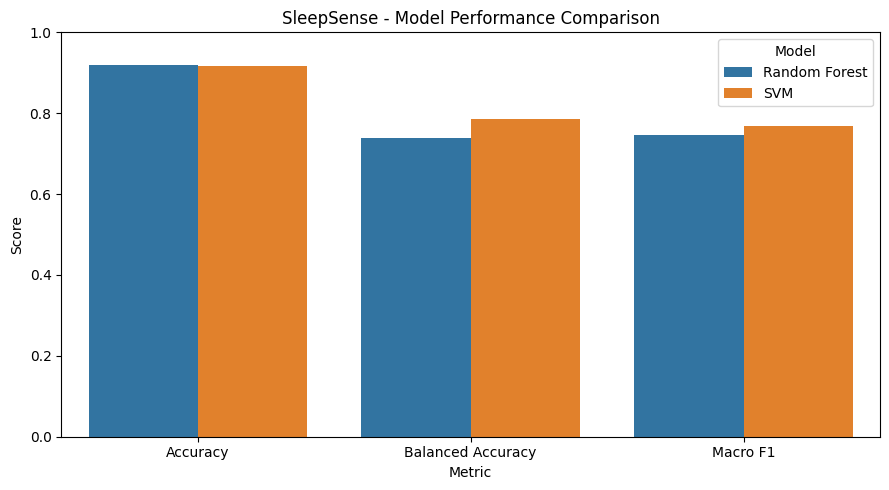

In [10]:
#Model performance chart
plt.figure(figsize=(9, 5))

comparison_long = comparison_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1"
    ],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=comparison_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1)
plt.title("SleepSense - Model Performance Comparison")
plt.tight_layout()
plt.show()

In [11]:
#Classification reports
for model_name, predictions in all_predictions.items():

    print(f"\n{model_name}")
    print("=" * 55)

    print(
        classification_report(
            y,
            predictions,
            labels=stage_order,
            zero_division=0
        )
    )


Random Forest
              precision    recall  f1-score   support

           W       0.99      0.98      0.98     11340
          N1       0.41      0.29      0.34       596
          N2       0.82      0.92      0.87      2792
          N3       0.89      0.84      0.86       932
         REM       0.71      0.67      0.69      1028

    accuracy                           0.92     16688
   macro avg       0.76      0.74      0.75     16688
weighted avg       0.91      0.92      0.92     16688


SVM
              precision    recall  f1-score   support

           W       0.99      0.98      0.98     11340
          N1       0.34      0.48      0.40       596
          N2       0.92      0.85      0.88      2792
          N3       0.78      0.90      0.84       932
         REM       0.74      0.73      0.74      1028

    accuracy                           0.92     16688
   macro avg       0.76      0.79      0.77     16688
weighted avg       0.93      0.92      0.92     16688



**Confusion matrices**

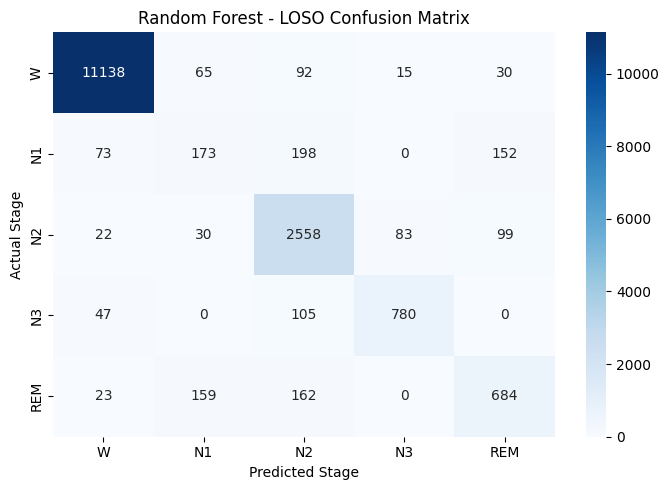

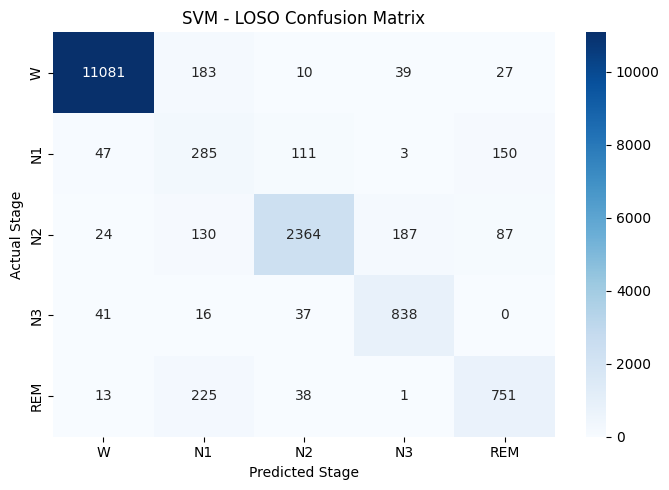

In [12]:
#Visualize both models
for model_name, predictions in all_predictions.items():

    cm = confusion_matrix(
        y,
        predictions,
        labels=stage_order
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=stage_order,
        yticklabels=stage_order
    )

    plt.xlabel("Predicted Stage")
    plt.ylabel("Actual Stage")
    plt.title(f"{model_name} - LOSO Confusion Matrix")

    plt.tight_layout()
    plt.show()

In [13]:
#saving results
output_dir = "/content/sleepsense/model_comparison"

os.makedirs(output_dir, exist_ok=True)

comparison_df.to_csv(
    f"{output_dir}/model_comparison.csv",
    index=False
)

fold_comparison_df.to_csv(
    f"{output_dir}/participant_comparison.csv",
    index=False
)

for model_name, predictions in all_predictions.items():

    safe_name = model_name.lower().replace(" ", "_")

    prediction_df = df[
        ["subject_id", "recording_id", "sleep_stage"]
    ].copy()

    prediction_df["predicted_stage"] = predictions

    prediction_df.to_csv(
        f"{output_dir}/{safe_name}_predictions.csv",
        index=False
    )

print("Comparison outputs saved.")

Comparison outputs saved.


In [14]:
print("OVERALL COMPARISON")
display(comparison_df.round(4))

print("\nPARTICIPANT-WISE COMPARISON")
display(
    fold_comparison_df.pivot(
        index="subject_id",
        columns="Model",
        values="macro_f1"
    ).round(4)
)

OVERALL COMPARISON


,Model,Accuracy,Balanced Accuracy,Macro F1,Cohen Kappa
0,Random Forest,0.9188,0.7382,0.7473,0.8380
1,SVM,0.9180,0.7863,0.7674,0.8388



PARTICIPANT-WISE COMPARISON


Model,Random Forest,SVM
subject_id,,
SC4001,0.6946,0.7770
SC4002,0.5899,0.6693
SC4011,0.8441,0.8321
SC4012,0.7892,0.7774
SC4021,0.7752,0.7588
SC4022,0.6501,0.7459


In [15]:
import shutil
from google.colab import files
import os

output_dir = "/content/sleepsense/model_comparison"

zip_path = shutil.make_archive(
    "/content/SleepSense_Model_Comparison",
    "zip",
    output_dir
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>